# All-league first-half goal price response

This notebook tests whether the EPL pilot's scoring-team win-price response appears in the full candidate-fixture inventory. The event table covers every FotMob goal in every successfully matched fixture; the primary analysis deliberately uses only the match's **opening goal when it occurs in the first half**.

All event timestamps are built from FotMob event clocks and half-start anchors before prices are loaded. Unreliable UTC bounds remain blank. Price changes are strictly observed before and after the goal interval; nothing is interpolated or shifted to a price move. Controls are nearest same-half, goal-free windows selected only by event timing and price coverage.

Regenerate the caches and CSV datasets from the repository root:
```bash
python3 scripts/build_soccer_goal_event_study_data.py
```
Then execute this notebook top-to-bottom in VS Code, or run:
```bash
python3 -m jupyter nbconvert --to notebook --execute --inplace notebooks/soccer_goal_event_study.ipynb
```
The builder reuses local FotMob/Gamma/CLOB caches and fetches missing records. The notebook itself only reads saved CSVs.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'Sports-Market-Capstone', Path.cwd().parent / 'Sports-Market-Capstone']
ROOT = next((p.resolve() for p in root_candidates if (p / 'data/processed/soccer_goal_fixture_coverage.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run the notebook from the project or notebooks directory after building the CSV datasets.')
PROCESSED = ROOT / 'data' / 'processed'
goals = pd.read_csv(PROCESSED / 'soccer_all_goals.csv', dtype={'fixture_id': str, 'fotmob_event_id': str}, keep_default_na=False)
coverage = pd.read_csv(PROCESSED / 'soccer_goal_fixture_coverage.csv', dtype={'fixture_id': str}, keep_default_na=False)
prices = pd.read_csv(PROCESSED / 'soccer_goal_event_price_history.csv', dtype={'fixture_id': str, 'token_id': str}, keep_default_na=False)
pilot_path = PROCESSED / 'soccer_goal_response_pilot.csv'
pilot_ids = set(pd.read_csv(pilot_path, dtype={'fixture_id': str})['fixture_id']) if pilot_path.exists() else set()

for frame, columns in ((goals, ['goal_utc_lower', 'goal_utc_upper']), (coverage, ['half_start_utc', 'half_end_utc']), (prices, ['observation_timestamp_utc'])):
    for column in columns:
        if column in frame:
            frame[column + '_dt'] = pd.to_datetime(frame[column], utc=True, errors='coerce')
if not prices.empty:
    prices['probability'] = pd.to_numeric(prices['probability'], errors='coerce')
    prices = prices[prices['probability'].between(0, 1)].copy()
    prices = prices[prices['token_mapping_status'].isin(['matched', 'matched_existing_draw_mapping'])].copy()
    prices = prices.sort_values('observation_timestamp_utc_dt')

print(f'Project root: {ROOT}')
print(f'Candidate fixtures: {len(coverage):,}; all-goal rows: {len(goals):,}; price observations: {len(prices):,}; pilot fixtures: {len(pilot_ids)}')

Project root: /Users/pabloherreramendez/Desktop/sports_market_capstone/Sports-Market-Capstone
Candidate fixtures: 2,303; all-goal rows: 3,589; price observations: 51,141; pilot fixtures: 15


## Fixed measurement rules

- Freshness is at most **5 minutes**. The goal move uses the nearest scoring-team win-price observation strictly before the UTC goal interval and the first strictly after it.
- The goal interval is the event's one-minute FotMob interval. The associated display window is that interval plus **3 minutes on each side**. The control is an equally long (7-minute) goal-free window from the same first half. For widened timing, the event interval is prespecified at 3 minutes (one extra minute on either side), and the control/display window expands equally to 9 minutes.
- A control must have fresh bracket observations, avoid the goal display window, and not overlap any first-half goal interval. Among eligible controls, choose the window nearest the event by midpoint, then the earliest start. Price magnitudes never enter control selection.
- Bootstrap intervals resample paired fixtures with replacement (10,000 draws; fixed seed). Moves and paired differences are reported in percentage points.
- The 15 original pilot fixture IDs are read from the saved pilot CSV and excluded in a separate primary analysis. The clock-anchor subset only accepts anchors with an explicit timezone-aware timestamp or explicit timezone; schedule-inferred offsets are not classed as independent verification.

In [2]:
FRESH_MINUTES = 5.0
DISPLAY_PAD_MINUTES = 3
BOOTSTRAP_DRAWS = 10_000
BOOTSTRAP_SEED = 20261123
PERIOD_ORDER = {'FirstHalf': 1, 'SecondHalf': 2, 'FirstExtraHalf': 3, 'SecondExtraHalf': 4}

def fresh_bracket(series, start, end):
    if series.empty or pd.isna(start) or pd.isna(end):
        return None, None, 'price_history_missing'
    before = series[series['observation_timestamp_utc_dt'] < start]
    after = series[series['observation_timestamp_utc_dt'] > end]
    if before.empty or after.empty:
        return None, None, 'missing_strict_pre_or_post_observation'
    pre, post = before.iloc[-1], after.iloc[0]
    pre_age = (start - pre['observation_timestamp_utc_dt']).total_seconds() / 60
    post_age = (post['observation_timestamp_utc_dt'] - end).total_seconds() / 60
    if pre_age > FRESH_MINUTES or post_age > FRESH_MINUTES:
        return None, None, 'stale_pre_or_post_observation'
    return (pre, post, pre_age, post_age), None, 'measured'

def bracket_fields(bracket):
    if bracket is None:
        return {'before_timestamp_utc': None, 'after_timestamp_utc': None, 'before_distance_minutes': None, 'after_distance_minutes': None, 'move': None}
    pre, post, pre_age, post_age = bracket
    return {'before_timestamp_utc': pre['observation_timestamp_utc_dt'].isoformat(), 'after_timestamp_utc': post['observation_timestamp_utc_dt'].isoformat(), 'before_distance_minutes': pre_age, 'after_distance_minutes': post_age, 'move': float(post['probability'] - pre['probability'])}

def choose_control(series, goal_plot_start, goal_plot_end, half_start, half_end, goal_intervals):
    duration = goal_plot_end - goal_plot_start
    latest = half_end - duration
    if latest < half_start:
        return None, None, 'first_half_too_short_for_control'
    candidates = []
    start = half_start
    while start <= latest:
        end = start + duration
        disjoint_from_event = end <= goal_plot_start or start >= goal_plot_end
        goal_free = not any(start < g_end and end > g_start for g_start, g_end in goal_intervals)
        if disjoint_from_event and goal_free:
            bracket, _, status = fresh_bracket(series, start, end)
            if bracket is not None:
                distance = abs(((start + duration / 2) - (goal_plot_start + (goal_plot_end - goal_plot_start) / 2)).total_seconds())
                candidates.append((distance, start, end, bracket))
        start += pd.Timedelta(minutes=1)
    if not candidates:
        return None, None, 'no_goal_free_control_with_fresh_prices'
    _, chosen_start, chosen_end, chosen_bracket = min(candidates, key=lambda x: (x[0], x[1]))
    return (chosen_start, chosen_end, chosen_bracket), None, 'measured'

def fixture_measurement(fixture_row, fixture_goals, all_fixture_goals, price_rows, widen_minutes=0):
    result = {
        'fixture_id': fixture_row['fixture_id'], 'league': fixture_row['league'],
        'match_date': fixture_row['match_date'], 'home_team': fixture_row['home_team'], 'away_team': fixture_row['away_team'],
        'fotmob_match_id': fixture_row.get('fotmob_match_id'), 'goal_event_id': None,
        'goal_period': None, 'goal_display_minute': None, 'scoring_side': None,
        'goal_interval_start_utc': None, 'goal_interval_end_utc': None,
        'goal_plot_start_utc': None, 'goal_plot_end_utc': None,
        'goal_before_timestamp_utc': None, 'goal_after_timestamp_utc': None,
        'goal_before_distance_minutes': None, 'goal_after_distance_minutes': None, 'goal_move': None,
        'control_start_utc': None, 'control_end_utc': None,
        'control_before_timestamp_utc': None, 'control_after_timestamp_utc': None,
        'control_before_distance_minutes': None, 'control_after_distance_minutes': None, 'control_move': None,
        'price_history_status': fixture_row.get('price_history_status'), 'exclusion_reasons': ''
    }
    reasons = []
    if fixture_goals.empty:
        reasons.append('no_confirmed_goal_or_event_feed_unavailable')
        result['exclusion_reasons'] = ';'.join(reasons)
        return result
    opening = fixture_goals.iloc[0]
    result.update({'goal_event_id': opening.get('fotmob_event_id'), 'goal_period': opening.get('period'), 'goal_display_minute': opening.get('displayed_goal_minute'), 'scoring_side': opening.get('scoring_side')})
    if opening.get('period') != 'FirstHalf':
        reasons.append('opening_goal_not_in_first_half')
    lower, upper = opening.get('goal_utc_lower_dt'), opening.get('goal_utc_upper_dt')
    if pd.isna(lower) or pd.isna(upper):
        reasons.append('opening_goal_utc_bounds_unavailable')
    side = opening.get('scoring_side')
    if side not in ('home', 'away'):
        reasons.append('opening_goal_scoring_side_unavailable')
    if reasons:
        result['exclusion_reasons'] = ';'.join(reasons)
        return result
    lower = lower - pd.Timedelta(minutes=widen_minutes)
    upper = upper + pd.Timedelta(minutes=widen_minutes)
    plot_start = lower - pd.Timedelta(minutes=DISPLAY_PAD_MINUTES)
    plot_end = upper + pd.Timedelta(minutes=DISPLAY_PAD_MINUTES)
    result.update({'goal_interval_start_utc': lower.isoformat(), 'goal_interval_end_utc': upper.isoformat(), 'goal_plot_start_utc': plot_start.isoformat(), 'goal_plot_end_utc': plot_end.isoformat()})
    series = price_rows[price_rows['outcome'].eq(side)].copy() if not price_rows.empty else pd.DataFrame()
    if series.empty:
        reasons.append('scoring_team_win_price_history_unavailable')
    goal_bracket, _, goal_status = fresh_bracket(series, lower, upper)
    if goal_bracket is None:
        reasons.append('goal_window_' + goal_status)
    else:
        fields = bracket_fields(goal_bracket)
        for name, value in fields.items():
            result['goal_' + name] = value
    half_start, half_end = fixture_row.get('half_start_utc_dt'), fixture_row.get('half_end_utc_dt')
    if pd.isna(half_start):
        reasons.append('first_half_start_utc_unavailable')
    if pd.isna(half_end) and not pd.isna(half_start):
        half_end = half_start + pd.Timedelta(minutes=45)
    if pd.isna(half_end):
        reasons.append('first_half_end_utc_unavailable')
    if not reasons:
        intervals = []
        for _, event in all_fixture_goals.iterrows():
            if event.get('period') != 'FirstHalf':
                continue
            g_start, g_end = event.get('goal_utc_lower_dt'), event.get('goal_utc_upper_dt')
            if pd.isna(g_start) or pd.isna(g_end):
                continue
            intervals.append((g_start - pd.Timedelta(minutes=widen_minutes), g_end + pd.Timedelta(minutes=widen_minutes)))
        control, _, control_status = choose_control(series, plot_start, plot_end, half_start, half_end, intervals)
        if control is None:
            reasons.append(control_status)
        else:
            control_start, control_end, control_bracket = control
            result['control_start_utc'] = control_start.isoformat()
            result['control_end_utc'] = control_end.isoformat()
            for name, value in bracket_fields(control_bracket).items():
                result['control_' + name] = value
    result['exclusion_reasons'] = ';'.join(dict.fromkeys(reasons))
    return result

def analyze_all(widen_minutes=0):
    goal_groups = {str(fid): group.sort_values('goal_order') for fid, group in goals.groupby('fixture_id')}
    price_groups = {str(fid): group for fid, group in prices.groupby('fixture_id')}
    rows = []
    for fixture in coverage.to_dict('records'):
        fid = str(fixture['fixture_id'])
        rows.append(fixture_measurement(fixture, goal_groups.get(fid, goals.iloc[0:0]), goal_groups.get(fid, goals.iloc[0:0]), price_groups.get(fid, prices.iloc[0:0]), widen_minutes))
    return pd.DataFrame(rows)

primary = analyze_all(widen_minutes=0)
wide = analyze_all(widen_minutes=1)
print(f'Primary usable pairs: {primary[primary.goal_move.notna() & primary.control_move.notna()].shape[0]:,}')
print(f'Widened usable pairs: {wide[wide.goal_move.notna() & wide.control_move.notna()].shape[0]:,}')

Primary usable pairs: 857
Widened usable pairs: 856


In [3]:
goal_groups = {str(fid): group.sort_values('goal_order') for fid, group in goals.groupby('fixture_id')}
first_goal = goals.sort_values(['fixture_id', 'goal_order']).drop_duplicates('fixture_id', keep='first') if not goals.empty else goals
first_half_opening_ids = set(first_goal.loc[first_goal['period'].eq('FirstHalf'), 'fixture_id'].astype(str)) if not first_goal.empty else set()
matched_count = coverage['fotmob_match_status'].astype(str).str.startswith('matched_').sum()
coverage_steps = pd.DataFrame([
    ('Candidate fixtures', len(coverage)),
    ('FotMob uniquely matched', int(matched_count)),
    ('Matched with event-feed response', int(coverage['event_feed_status'].isin(['available', 'available_confirmed_scoreless', 'available_no_goal_events_score_nonzero']).sum())),
    ('Confirmed scoreless fixtures', int(coverage['scoreless_confirmed'].astype(str).str.casefold().eq('true').sum())),
    ('Fixtures with extracted goals', int(coverage['goal_count'].astype(int).gt(0).sum())),
    ('Opening goal in first half', len(first_half_opening_ids)),
    ('Opening first-half goal with UTC bounds', len(first_half_opening_ids.intersection(set(coverage.loc[coverage['opening_goal_utc_lower'].astype(str).ne(''), 'fixture_id'].astype(str))))),
    ('Opening-goal scoring-team price history available', int(coverage['price_history_status'].isin(['history_available', 'reused_verified_cached_win_history']).sum())),
    ('Primary usable goal/control pairs', int((primary.goal_move.notna() & primary.control_move.notna()).sum())),
], columns=['step', 'fixtures'])
display(coverage_steps)

exclusion_counts = (coverage.assign(reason=coverage['exclusion_reasons'].replace('', 'none').str.split(';'))
    .explode('reason').groupby('reason').size().sort_values(ascending=False).rename('fixtures').reset_index())
display(exclusion_counts.head(15))

wide_csv = wide.add_prefix('wide_').rename(columns={'wide_fixture_id': 'fixture_id'})
analysis = primary.merge(wide_csv, on='fixture_id', how='left', validate='one_to_one')
analysis['original_pilot_fixture'] = analysis['fixture_id'].isin(pilot_ids)
analysis.to_csv(PROCESSED / 'soccer_goal_event_study_analysis.csv', index=False)
print(f"Saved fixture-level audit: {PROCESSED / 'soccer_goal_event_study_analysis.csv'}")

,step,fixtures
0,Candidate fixtures,2303
1,FotMob uniquely matched,1260
2,Matched with event-feed response,1260
3,Confirmed scoreless fixtures,77
4,Fixtures with extracted goals,1183
5,Opening goal in first half,889
6,Opening first-half goal with UTC bounds,885
7,Opening-goal scoring-team price history available,859
8,Primary usable goal/control pairs,857


,reason,fixtures
0,none,1230
1,fotmob_match_not_found,1043
2,scoring_team_win_price_history_unavailable,26
3,opening_goal_utc_bounds_unavailable,4


Saved fixture-level audit: /Users/pabloherreramendez/Desktop/sports_market_capstone/Sports-Market-Capstone/data/processed/soccer_goal_event_study_analysis.csv


In [4]:
def paired_subset(frame):
    return frame[frame['goal_move'].notna() & frame['control_move'].notna()].copy()

def summary_metrics(frame, label):
    paired = paired_subset(frame)
    n = len(paired)
    out = {'analysis': label, 'n_fixtures': n, 'median_goal_move_pp': np.nan, 'goal_positive_share': np.nan,
           'median_control_move_pp': np.nan, 'control_positive_share': np.nan, 'median_difference_pp': np.nan,
           'difference_ci95_low_pp': np.nan, 'difference_ci95_high_pp': np.nan, 'share_goal_gt_control': np.nan}
    if n == 0:
        return out
    goal = paired['goal_move'].to_numpy(dtype=float) * 100
    control = paired['control_move'].to_numpy(dtype=float) * 100
    difference = goal - control
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    bootstrap_medians = []
    for start in range(0, BOOTSTRAP_DRAWS, 250):
        draws = min(250, BOOTSTRAP_DRAWS - start)
        samples = rng.choice(difference, size=(draws, n), replace=True)
        bootstrap_medians.extend(np.median(samples, axis=1))
    low, high = np.quantile(bootstrap_medians, [0.025, 0.975])
    out.update({'median_goal_move_pp': float(np.median(goal)), 'goal_positive_share': float(np.mean(goal > 0)),
                'median_control_move_pp': float(np.median(control)), 'control_positive_share': float(np.mean(control > 0)),
                'median_difference_pp': float(np.median(difference)), 'difference_ci95_low_pp': float(low),
                'difference_ci95_high_pp': float(high), 'share_goal_gt_control': float(np.mean(difference > 0))})
    return out

primary_usable = paired_subset(primary)
wide_usable = paired_subset(wide)
common_ids = set(primary_usable['fixture_id']) & set(wide_usable['fixture_id'])
primary_common = primary[primary['fixture_id'].isin(common_ids)]
wide_common = wide[wide['fixture_id'].isin(common_ids)]
without_pilot = primary[~primary['fixture_id'].isin(pilot_ids)]
independent_ids = set(coverage.loc[coverage['independently_verified_clock_anchor'].astype(str).str.casefold().eq('true'), 'fixture_id'].astype(str))
independent = primary[primary['fixture_id'].isin(independent_ids)]

sensitivity = pd.DataFrame([
    summary_metrics(primary, 'Primary: full usable sample'),
    summary_metrics(without_pilot, 'Primary: excluding original 15 pilot fixtures'),
    summary_metrics(primary_common, 'Primary timing: common primary/wide fixtures'),
    summary_metrics(wide_common, 'Wider timing: common primary/wide fixtures'),
    summary_metrics(wide, 'Wider timing: full usable sample'),
    summary_metrics(independent, 'Primary: independently verified clock anchors'),
])
display(sensitivity.round(3))
print(f'Fixtures with independently verified half-start anchors: {len(independent_ids)}; usable paired fixtures in this subset: {len(paired_subset(independent))}.')

,analysis,n_fixtures,median_goal_move_pp,goal_positive_share,median_control_move_pp,control_positive_share,median_difference_pp,difference_ci95_low_pp,difference_ci95_high_pp,share_goal_gt_control
0,Primary: full usable sample,857,20.5,0.967,-0.5,0.362,20.5,20.0,21.0,0.944
1,Primary: excluding original 15 pilot fixtures,846,20.5,0.967,-0.5,0.357,20.5,20.0,21.0,0.944
2,Primary timing: common primary/wide fixtures,856,20.5,0.967,-0.5,0.362,20.5,20.0,21.0,0.944
3,Wider timing: common primary/wide fixtures,856,21.0,0.984,-0.5,0.346,21.0,21.0,22.0,0.979
4,Wider timing: full usable sample,856,21.0,0.984,-0.5,0.346,21.0,21.0,22.0,0.979
5,Primary: independently verified clock anchors,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Fixtures with independently verified half-start anchors: 0; usable paired fixtures in this subset: 0.


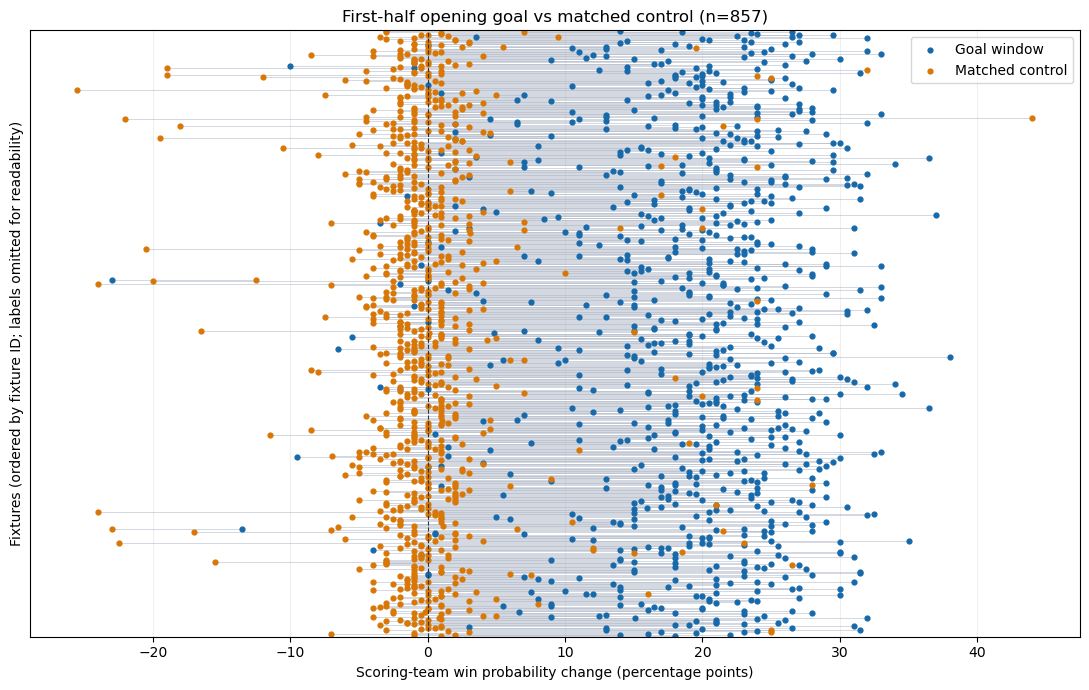

Saved pooled paired plot: /Users/pabloherreramendez/Desktop/sports_market_capstone/Sports-Market-Capstone/data/processed/soccer_goal_event_study_paired.png


In [5]:
plot_data = primary_usable.sort_values('fixture_id').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 7))
if not plot_data.empty:
    goal_pp = plot_data['goal_move'].to_numpy(dtype=float) * 100
    control_pp = plot_data['control_move'].to_numpy(dtype=float) * 100
    y = np.arange(len(plot_data))
    for yi, g, c in zip(y, goal_pp, control_pp):
        ax.plot([g, c], [yi, yi], color='#aab4c3', linewidth=0.65, alpha=0.55, zorder=1)
    ax.scatter(goal_pp, y, s=12, color='#1769aa', label='Goal window', zorder=2)
    ax.scatter(control_pp, y, s=12, color='#d97706', label='Matched control', zorder=2)
    ax.set_ylim(-1, len(plot_data))
    ax.set_yticks([])
    ax.legend(loc='best')
else:
    ax.text(0.5, 0.5, 'No usable paired fixtures', ha='center', va='center', transform=ax.transAxes)
ax.axvline(0, color='#333333', linewidth=0.8, linestyle='--')
ax.set_xlabel('Scoring-team win probability change (percentage points)')
ax.set_ylabel('Fixtures (ordered by fixture ID; labels omitted for readability)')
ax.set_title(f'First-half opening goal vs matched control (n={len(plot_data)})')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
paired_plot_path = PROCESSED / 'soccer_goal_event_study_paired.png'
fig.savefig(paired_plot_path, dpi=180)
plt.show()
print(f'Saved pooled paired plot: {paired_plot_path}')

In [6]:
n = len(primary_usable)
metrics = summary_metrics(primary, 'primary')
if n < 5:
    replication = 'Insufficient usable paired coverage to determine replication.'
elif metrics['median_difference_pp'] > 0 and metrics['share_goal_gt_control'] >= 2 / 3:
    replication = 'The pilot direction replicated descriptively: median paired goal-minus-control move is positive and at least two-thirds of goal moves exceed their controls.'
else:
    replication = 'The pilot directional heuristic did not replicate: goal and control moves show heavy overlap or the paired difference is not consistently positive.'
wide_metrics = summary_metrics(wide, 'wide')
if wide_metrics['n_fixtures'] >= 5 and metrics['n_fixtures'] >= 5:
    timing_note = (f"Widening the goal interval changed the median paired difference from {metrics['median_difference_pp']:.2f} pp "
                   f"(n={metrics['n_fixtures']}) to {wide_metrics['median_difference_pp']:.2f} pp "
                   f"(n={wide_metrics['n_fixtures']}); compare the common-fixture rows above for sample-stable sensitivity.")
else:
    timing_note = 'Timestamp-alignment sensitivity is limited by the small usable sample under at least one timing setting.'
if len(paired_subset(independent)) < 5:
    verified_note = (f"Only {len(paired_subset(independent))} usable pairs have independently verified clock anchors "
                    f"({len(independent_ids)} fixtures with such anchors); this is below the prespecified five-pair minimum. "
                    'The remaining timing uncertainty is the timezone/UTC alignment of FotMob half-start strings; kickoff-inferred offsets are not independent verification.')
else:
    verified_note = 'The independently verified clock-anchor subset is large enough for a separate sensitivity estimate; see the table.'
print('Conclusion')
print(replication)
print(timing_note)
print(verified_note)
print(f"Primary median goal move: {metrics['median_goal_move_pp']:.2f} pp; positive share: {metrics['goal_positive_share']:.1%}.")
print(f"Primary median control move: {metrics['median_control_move_pp']:.2f} pp; positive share: {metrics['control_positive_share']:.1%}.")
print(f"Median paired difference: {metrics['median_difference_pp']:.2f} pp; fixture-bootstrap 95% interval: [{metrics['difference_ci95_low_pp']:.2f}, {metrics['difference_ci95_high_pp']:.2f}] pp; goal move exceeded control in {metrics['share_goal_gt_control']:.1%} of pairs.")
print('\nThis is a descriptive replication/feasibility test, not a claim of market overreaction. Threshold selection and whole-half jump scanning are out of scope.')

Conclusion
The pilot direction replicated descriptively: median paired goal-minus-control move is positive and at least two-thirds of goal moves exceed their controls.
Widening the goal interval changed the median paired difference from 20.50 pp (n=857) to 21.00 pp (n=856); compare the common-fixture rows above for sample-stable sensitivity.
Only 0 usable pairs have independently verified clock anchors (0 fixtures with such anchors); this is below the prespecified five-pair minimum. The remaining timing uncertainty is the timezone/UTC alignment of FotMob half-start strings; kickoff-inferred offsets are not independent verification.
Primary median goal move: 20.50 pp; positive share: 96.7%.
Primary median control move: -0.50 pp; positive share: 36.2%.
Median paired difference: 20.50 pp; fixture-bootstrap 95% interval: [20.00, 21.00] pp; goal move exceeded control in 94.4% of pairs.

This is a descriptive replication/feasibility test, not a claim of market overreaction. Threshold selecti

## Additional views: first-half opening goals

These figures use only the usable **first-half opening-goal** pairs from the primary timing rule. The distribution and league views are descriptive. The sample price paths use the first fixture ID in each league that has at least five scoring-team price observations within the fixed seven-minute goal display window; this rule depends on identity and coverage, never on price movement.

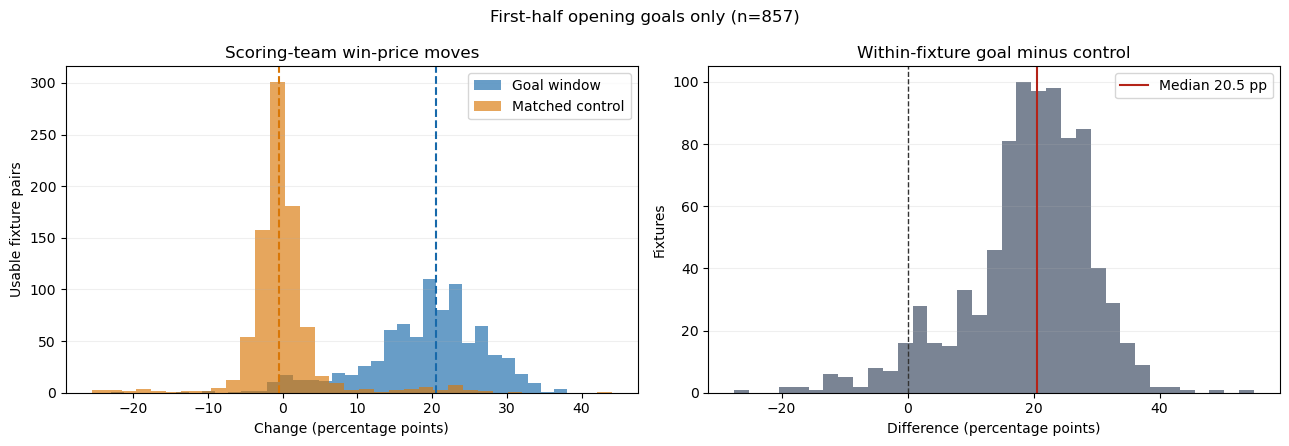

Saved move-distribution figure: /Users/pabloherreramendez/Desktop/sports_market_capstone/Sports-Market-Capstone/data/processed/soccer_goal_event_study_move_distributions.png


In [7]:
goal_moves_pp = primary_usable['goal_move'].to_numpy(dtype=float) * 100
control_moves_pp = primary_usable['control_move'].to_numpy(dtype=float) * 100
paired_differences_pp = goal_moves_pp - control_moves_pp

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(goal_moves_pp, bins=35, alpha=0.65, color='#1769aa', label='Goal window')
axes[0].hist(control_moves_pp, bins=35, alpha=0.65, color='#d97706', label='Matched control')
axes[0].axvline(np.median(goal_moves_pp), color='#1769aa', linestyle='--', linewidth=1.5)
axes[0].axvline(np.median(control_moves_pp), color='#d97706', linestyle='--', linewidth=1.5)
axes[0].set(title='Scoring-team win-price moves', xlabel='Change (percentage points)', ylabel='Usable fixture pairs')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.2)

axes[1].hist(paired_differences_pp, bins=35, color='#596579', alpha=0.8)
axes[1].axvline(0, color='#333333', linestyle='--', linewidth=1)
axes[1].axvline(np.median(paired_differences_pp), color='#b42318', linestyle='-', linewidth=1.5, label=f'Median {np.median(paired_differences_pp):.1f} pp')
axes[1].set(title='Within-fixture goal minus control', xlabel='Difference (percentage points)', ylabel='Fixtures')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.2)
fig.suptitle(f'First-half opening goals only (n={len(primary_usable)})')
fig.tight_layout()
distribution_plot_path = PROCESSED / 'soccer_goal_event_study_move_distributions.png'
fig.savefig(distribution_plot_path, dpi=180)
plt.show()
print(f'Saved move-distribution figure: {distribution_plot_path}')

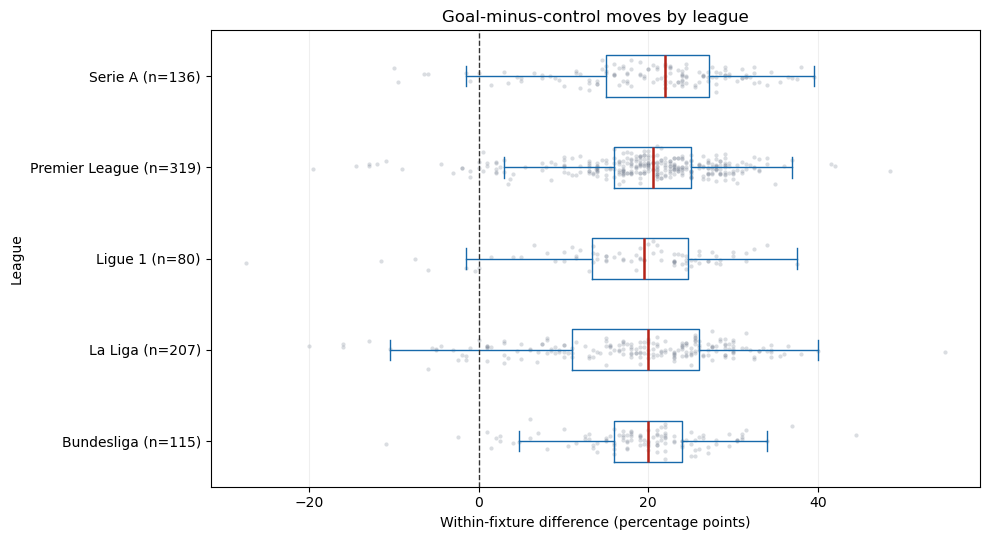

Saved league comparison figure: /Users/pabloherreramendez/Desktop/sports_market_capstone/Sports-Market-Capstone/data/processed/soccer_goal_event_study_league_differences.png


In [8]:
league_order = sorted(primary_usable['league'].dropna().unique())
league_differences = [
    (primary_usable.loc[primary_usable['league'].eq(league), 'goal_move'] -
     primary_usable.loc[primary_usable['league'].eq(league), 'control_move']).to_numpy(dtype=float) * 100
    for league in league_order
]
league_labels = [f'{league} (n={len(values)})' for league, values in zip(league_order, league_differences)]
rng = np.random.default_rng(BOOTSTRAP_SEED)
fig, ax = plt.subplots(figsize=(10, 5.5))
positions = np.arange(1, len(league_order) + 1)
for position, values in zip(positions, league_differences):
    jitter = rng.normal(0, 0.07, size=len(values))
    ax.scatter(values, position + jitter, s=9, alpha=0.22, color='#596579', linewidths=0)
ax.boxplot(league_differences, vert=False, positions=positions, widths=0.45, showfliers=False,
           medianprops={'color': '#b42318', 'linewidth': 1.8},
           boxprops={'color': '#1769aa'}, whiskerprops={'color': '#1769aa'},
           capprops={'color': '#1769aa'})
ax.set_yticks(positions, league_labels)
ax.axvline(0, color='#333333', linestyle='--', linewidth=1)
ax.set(title='Goal-minus-control moves by league', xlabel='Within-fixture difference (percentage points)', ylabel='League')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
league_plot_path = PROCESSED / 'soccer_goal_event_study_league_differences.png'
fig.savefig(league_plot_path, dpi=180)
plt.show()
print(f'Saved league comparison figure: {league_plot_path}')

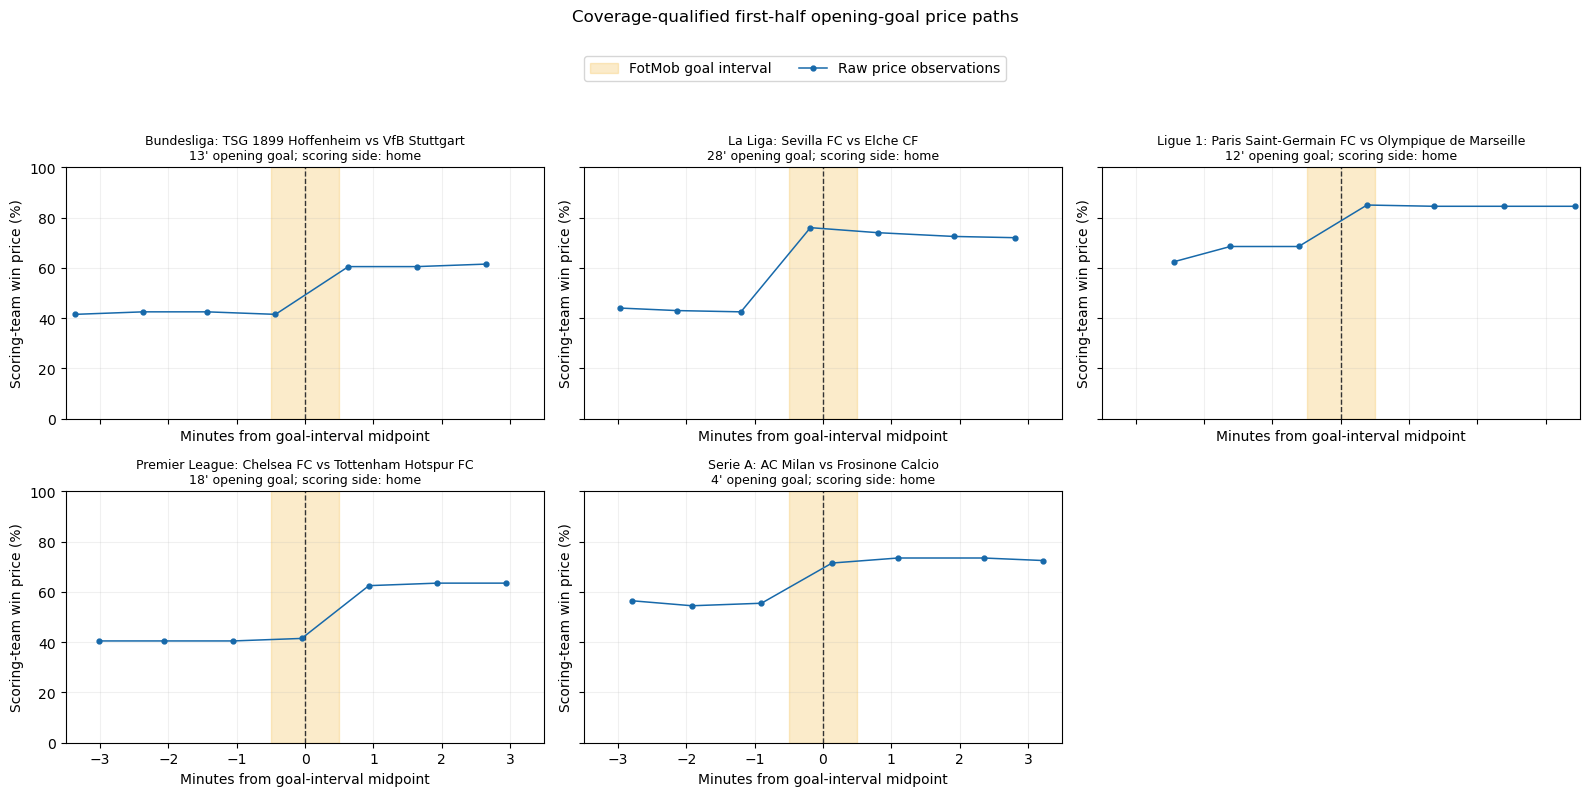

Examples selected by league then fixture ID, requiring >=5 observations in the fixed event display window:
        league              fixture_id                                            match scoring_side  price_observations
    Bundesliga fx-041cfa06b46afdb77b6b             TSG 1899 Hoffenheim vs VfB Stuttgart         home                   7
       La Liga fx-01ff1937e87b31c76951                           Sevilla FC vs Elche CF         home                   7
       Ligue 1 fx-007dabec712730794ee3 Paris Saint-Germain FC vs Olympique de Marseille         home                   7
Premier League fx-0059a12986a8f9ade5be               Chelsea FC vs Tottenham Hotspur FC         home                   7
       Serie A fx-001e45b8832315b14dcf                     AC Milan vs Frosinone Calcio         home                   7
Saved example price paths: /Users/pabloherreramendez/Desktop/sports_market_capstone/Sports-Market-Capstone/data/processed/soccer_goal_event_study_example_price_paths.p

In [9]:
example_rows = []
for league in sorted(primary_usable['league'].dropna().unique()):
    candidates = primary_usable[primary_usable['league'].eq(league)].sort_values('fixture_id')
    for _, fixture in candidates.iterrows():
        interval_start = pd.to_datetime(fixture['goal_interval_start_utc'], utc=True)
        interval_end = pd.to_datetime(fixture['goal_interval_end_utc'], utc=True)
        eligible_prices = prices[
            prices['fixture_id'].eq(str(fixture['fixture_id'])) &
            prices['outcome'].eq(fixture['scoring_side']) &
            prices['observation_timestamp_utc_dt'].ge(interval_start - pd.Timedelta(minutes=3)) &
            prices['observation_timestamp_utc_dt'].le(interval_end + pd.Timedelta(minutes=3))
        ]
        if len(eligible_prices) >= 5:
            example_rows.append((fixture, eligible_prices.copy(), interval_start, interval_end))
            break

if not example_rows:
    raise ValueError('No usable first-half opening-goal examples have adequate price coverage.')

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
axes = axes.ravel()
for ax, (fixture, example_prices, interval_start, interval_end) in zip(axes, example_rows):
    center = interval_start + (interval_end - interval_start) / 2
    example_prices = example_prices.sort_values('observation_timestamp_utc_dt').copy()
    example_prices['minutes_from_goal_interval'] = (
        example_prices['observation_timestamp_utc_dt'] - center
    ).dt.total_seconds() / 60
    ax.axvspan((interval_start - center).total_seconds() / 60,
               (interval_end - center).total_seconds() / 60,
               color='#f4b942', alpha=0.28, label='FotMob goal interval')
    ax.axvline(0, color='#333333', linestyle='--', linewidth=1)
    ax.plot(example_prices['minutes_from_goal_interval'], example_prices['probability'] * 100,
            marker='o', markersize=3.5, linewidth=1.1, color='#1769aa', label='Raw price observations')
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(0, 100)
    ax.set_title(f"{fixture['league']}: {fixture['home_team']} vs {fixture['away_team']}\n"
                 f"{fixture['goal_display_minute']}' opening goal; scoring side: {fixture['scoring_side']}", fontsize=9)
    ax.grid(alpha=0.18)
    ax.set_xlabel('Minutes from goal-interval midpoint')
    ax.set_ylabel('Scoring-team win price (%)')
for ax in axes[len(example_rows):]:
    ax.remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.94))
fig.suptitle('Coverage-qualified first-half opening-goal price paths', y=0.99)
fig.tight_layout(rect=(0, 0, 1, 0.89))
example_plot_path = PROCESSED / 'soccer_goal_event_study_example_price_paths.png'
fig.savefig(example_plot_path, dpi=180)
plt.show()
print('Examples selected by league then fixture ID, requiring >=5 observations in the fixed event display window:')
print(pd.DataFrame([{
    'league': fixture['league'], 'fixture_id': fixture['fixture_id'],
    'match': f"{fixture['home_team']} vs {fixture['away_team']}",
    'scoring_side': fixture['scoring_side'], 'price_observations': len(example_prices)
} for fixture, example_prices, _, _ in example_rows]).to_string(index=False))
print(f'Saved example price paths: {example_plot_path}')